In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import Input,Conv2D,MaxPooling2D,Flatten,Dense
import tensorflow as tf

In [ ]:
data = './dataset /'
file = os.listdir(data)
print(file)

['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


In [3]:
x = []
y = []

In [4]:
for folder in file:
    folder_all = os.path.join(data,folder)
    # print(folder_all)
    for pic in os.listdir(folder_all):
        pic_all = os.path.join(folder_all,pic)
        # print(pic_all)
        im = cv2.imread(pic_all)
        im2 = cv2.resize(im,(28,28))
        im3 = cv2.cvtColor(im2,cv2.COLOR_BGR2GRAY)
        x.append(im3)
        y.append(int(folder))

In [5]:
x = np.array(x)
y = np.array(y)
y

array([0, 0, 0, ..., 9, 9, 9], shape=(77817,))

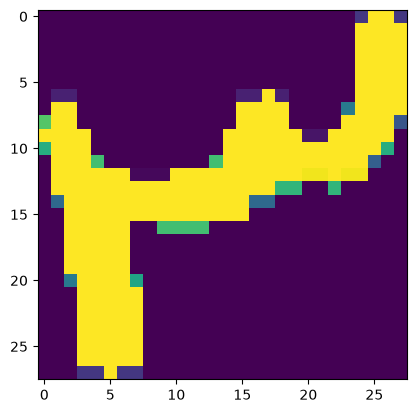

In [6]:
plt.imshow(x[30000])

In [7]:
x = x.astype('float32') / 255
print(x.shape)
x = np.expand_dims(x,axis=-1)
print(x.shape)

(77817, 28, 28)
(77817, 28, 28, 1)


In [8]:
x_train,x_test,y_train,y_test = train_test_split(x,y,
                                                 test_size=0.2,
                                                 random_state=42)

In [9]:
x_train.shape

(62253, 28, 28, 1)

In [10]:
model = Sequential([Input(shape=(28,28,1)),
                    Conv2D(32,(3,3),activation='relu'),
                    MaxPooling2D(),
                    Flatten(),
                    Dense(64,activation='relu'),
                    Dense(128,activation='relu'),
                    Dense(10,activation='softmax')])

model.summary()
model.compile(optimizer='adam',loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       346,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,106 (1.36 MB)

 Trainable params: 356,106 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.fit(x_train,y_train,epochs=10)

Epoch 1/10
1946/1946 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9684 - loss: 0.1036
Epoch 2/10
1946/1946 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9891 - loss: 0.0316
Epoch 3/10
1946/1946 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9938 - loss: 0.0181
Epoch 4/10
1946/1946 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9960 - loss: 0.0128
Epoch 5/10
1946/1946 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9974 - loss: 0.0081
Epoch 6/10
1946/1946 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9975 - loss: 0.0074
Epoch 7/10
1946/1946 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9981 - loss: 0.0058
Epoch 8/10
1946/1946 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9986 - loss: 0.0041
Epoch 9/10
1946/1946 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9987 - loss: 0.0040
Epoch 10/10
1946/1946 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9991 - loss: 0.0030


In [12]:
loss , accuracy = model.evaluate(x_test,y_test)
print('Loss Test:',round(loss*100,2))
print('Accuracy Test:',round(accuracy*100,2))

487/487 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9915 - loss: 0.0409
Loss Test: 4.09
Accuracy Test: 99.15


In [13]:
im = cv2.imread('test.jpg')
im2 = cv2.resize(im,(28,28))
im3 = cv2.cvtColor(im2,cv2.COLOR_BGR2GRAY)
img = 1 - im3
img.shape
img1 = img.astype('float32') / 255
img1 = np.expand_dims(img1,axis=0)
img1 = np.expand_dims(img1,axis=-1)
img1.shape

error: OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\resize.cpp:4217: error: (-215:Assertion failed) !ssize.empty() in function 'cv::resize'


In [ ]:
y_pred = model.predict(img1)
print(np.argmax(y_pred))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step
7


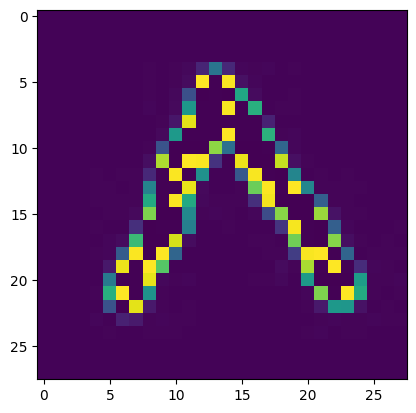

In [ ]:
plt.imshow(img)

In [ ]:
y_pred

array([[2.4247092e-05, 7.0949540e-07, 2.9619729e-05, 7.0477126e-06,
        2.5492915e-04, 7.0424485e-01, 7.7524019e-04, 6.6461494e-06,
        2.8554600e-01, 9.1107544e-03]], dtype=float32)

## تشخیص عدد دست‌نویس چندرقمی
سلول‌های اصلی دست‌نخورده‌اند. بعد از آموزش مدل، سلول‌های زیر را اجرا کنید.
تصویر باید یک خط عدد با زمینهٔ ساده و بدون حاشیه یا نوشتهٔ اضافی باشد. ترتیب رقم‌ها از چپ به راست است؛ مثلاً ۹۵۵۰.
تعداد رقم‌ها به‌صورت تقریبی از عرض تصویر تخمین زده می‌شود. برای رقم‌های متصل یا عرض‌های متفاوت، `n_digits=4` را بدهید. مرز برش با کمینه‌کردن جوهر روی مرز و متعادل‌کردن عرض‌ها انتخاب می‌شود؛ اتصال‌های پیچیده ممکن است اشتباه جدا شوند.
درصد نمایش‌داده‌شده خروجی مدل است و تضمین درستی نیست. دقت به شباهت تصویر ورودی و دادهٔ آموزش وابسته است.


In [ ]:
def read_number(path, n_digits=None):
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise ValueError("تصویر پیدا نشد: " + str(path))
    # ماسک با رقم سفید؛ تشخیص خودکار رنگ زمینه از لبه‌های تصویر
    _, mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if np.median(np.r_[mask[0], mask[-1], mask[:, 0], mask[:, -1]]) > 0:
        mask = 255 - mask
    points = cv2.findNonZero(mask)
    if points is None:
        raise ValueError("تصویر خالی است")
    x0, y0, w, h = cv2.boundingRect(points)
    mask = mask[y0:y0+h, x0:x0+w]
    ink = (mask > 0).sum(axis=0).astype(float)
    edges = np.diff(np.r_[False, ink > 0, False].astype(int))
    spans = list(zip(np.where(edges == 1)[0], np.where(edges == -1)[0]))
    if n_digits is None:
        # تخمین ساده برای بخش‌های عریض و به‌هم‌چسبیده؛ قابل اصلاح با n_digits
        n_digits = sum(max(1, int(round((b-a) / (0.65*h)))) for a, b in spans)
    if not isinstance(n_digits, (int, np.integer)) or not 1 <= n_digits <= w:
        raise ValueError("تعداد رقم‌ها باید عدد صحیح مثبت و حداکثر برابر عرض تصویر باشد")
    # انتخاب مرزها: جوهر کمتر در محل برش + عرض تقریباً متعادل
    target = w / n_digits
    dp = np.full((n_digits+1, w+1), np.inf)
    prev = np.zeros((n_digits+1, w+1), dtype=int)
    dp[0, 0] = 0
    for k in range(1, n_digits+1):
        for end in range(k, w+1):
            starts = np.arange(k-1, end)
            cost = dp[k-1, starts] + 0.15*((end-starts)/target - 1)**2
            if end < w:
                cost += (ink[end-1] + ink[end]) / (2*h)
            best = np.argmin(cost)
            dp[k, end], prev[k, end] = cost[best], starts[best]
    cuts = [w]
    for k in range(n_digits, 0, -1):
        cuts.append(int(prev[k, cuts[-1]]))
    cuts = cuts[::-1]
    # رنگ زمینه را با داده‌های آموزشی همین نوت‌بوک هماهنگ می‌کنیم
    train = np.asarray(x_train[:100])
    white_bg = np.median(np.concatenate([train[:, 0].ravel(), train[:, -1].ravel()])) > 0.5
    crops, boxes = [], []
    for a, b in zip(cuts[:-1], cuts[1:]):
        piece = mask[:, a:b]
        pts = cv2.findNonZero(piece)
        if pts is None:
            raise ValueError("یک برش خالی شد؛ تعداد رقم‌ها یا تصویر را بررسی کنید")
        px, py, pw, ph = cv2.boundingRect(pts)
        digit = cv2.resize(piece[py:py+ph, px:px+pw], (28, 28))
        crops.append((255-digit if white_bg else digit).astype('float32') / 255)
        boxes.append((x0+a+px, y0+py, pw, ph))
    probs = model.predict(np.asarray(crops)[..., None], verbose=0)
    labels = probs.argmax(axis=1)
    result = ''.join('۰۱۲۳۴۵۶۷۸۹'[i] for i in labels)
    fig, axes = plt.subplots(1, n_digits, figsize=(2*n_digits, 2), squeeze=False)
    for ax, crop, label, confidence in zip(axes[0], crops, labels, probs.max(axis=1)):
        ax.imshow(crop, cmap='gray'); ax.set_title(f'{label} ({confidence:.0%})'); ax.axis('off')
    plt.show()
    print("عدد تشخیص‌داده‌شده:", result)
    return result, boxes


In [ ]:
# مسیر تصویر عدد چندرقمی خودتان را وارد کنید
number, boxes = read_number('number.jpg', n_digits=4)
# برای تخمین خودکار تعداد: read_number('number.jpg')
